1. Fetch the artifact we just created (sample.csv) from W&B and read it with pandas:

In [1]:
import wandb
import pandas as pd
# Note that we use save_code=True in the call to wandb.init so the notebook is uploaded and versioned by W&B
run = wandb.init(project="nyc_airbnb", group="eda", save_code=True)
local_path = wandb.use_artifact("sample.csv:latest").file()
df = pd.read_csv(local_path)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/steffany/.netrc.
wandb: Currently logged in as: smcwate (smcwate-western-governors-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


2. Explore the data in df

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              20000 non-null  int64  
 1   name                            19993 non-null  object 
 2   host_id                         20000 non-null  int64  
 3   host_name                       19992 non-null  object 
 4   neighbourhood_group             20000 non-null  object 
 5   neighbourhood                   20000 non-null  object 
 6   latitude                        20000 non-null  float64
 7   longitude                       20000 non-null  float64
 8   room_type                       20000 non-null  object 
 9   price                           20000 non-null  int64  
 10  minimum_nights                  20000 non-null  int64  
 11  number_of_reviews               20000 non-null  int64  
 12  last_review                     

In [3]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,2.000000e+04,2.000000e+04,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,15877.000000,20000.000000,20000.000000
mean,1.892380e+07,6.746034e+07,40.728455,-73.952125,153.269050,6.992100,23.274100,1.377446,6.955450,112.901200
std,1.101223e+07,7.857936e+07,0.054755,0.046559,243.325609,21.645449,44.927793,1.683006,32.433831,131.762226
min,2.539000e+03,2.571000e+03,40.508730,-74.239140,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.393540e+06,7.853718e+06,40.689420,-73.983030,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.952117e+07,3.111431e+07,40.722730,-73.955640,105.000000,2.000000,5.000000,0.720000,1.000000,44.000000
75%,2.912936e+07,1.068426e+08,40.762990,-73.936380,175.000000,5.000000,23.000000,2.010000,2.000000,229.000000
max,3.648561e+07,2.742733e+08,40.913060,-73.717950,10000.000000,1250.000000,607.000000,27.950000,327.000000,365.000000


In [4]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,9138664,Private Lg Room 15 min to Manhattan,47594947,Iris,Queens,Sunnyside,40.74271,-73.92493,Private room,74,2,6,2019-05-26,0.13,1,5
1,31444015,TIME SQUARE CHARMING ONE BED IN HELL'S KITCHEN...,8523790,Johlex,Manhattan,Hell's Kitchen,40.76682,-73.98878,Entire home/apt,170,3,0,NaN,NaN,1,188
2,8741020,Voted #1 Location Quintessential 1BR W Village...,45854238,John,Manhattan,West Village,40.73631,-74.00611,Entire home/apt,245,3,51,2018-09-19,1.12,1,0
3,34602077,Spacious 1 bedroom apartment 15min from Manhattan,261055465,Regan,Queens,Astoria,40.76424,-73.92351,Entire home/apt,125,3,1,2019-05-24,0.65,1,13
4,23203149,Big beautiful bedroom in huge Bushwick apartment,143460,Megan,Brooklyn,Bushwick,40.69839,-73.92044,Private room,65,2,8,2019-06-23,0.52,2,8


In [5]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
19995,7094539,Tranquil haven in bubbly Brooklyn,2052211,Adriana,Brooklyn,Windsor Terrace,40.65360,-73.97546,Entire home/apt,143,14,2,2016-08-27,0.04,1,10
19996,4424261,Large 1 BR with backyard on UWS,3447311,Sarah,Manhattan,Upper West Side,40.80188,-73.96808,Entire home/apt,200,2,22,2019-05-21,0.50,1,0
19997,4545882,Amazing studio/Loft with a backyard,23569951,Kaveh,Manhattan,Upper East Side,40.78110,-73.94567,Entire home/apt,220,3,28,2019-05-23,0.50,1,293
19998,26518547,U2 comfortable double bed sleeps 2 guests,295128,Carol Gloria,Bronx,Clason Point,40.81225,-73.85502,Private room,80,1,4,2019-07-01,1.48,7,365
19999,33631782,Private Bedroom in Williamsburg Apt!,8569221,Andi,Brooklyn,Williamsburg,40.71829,-73.95819,Private room,109,3,3,2019-04-28,1.07,2,97


In [ ]:
# Which variables contain null values and how many?
df.isna().sum()

id                                   0
name                                 7
host_id                              0
host_name                            8
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       4123
reviews_per_month                 4123
calculated_host_listings_count       0
availability_365                     0
dtype: int64

In [8]:
# Find records with missing reviews_per_month or last_review values
missing_reviews = df[df['reviews_per_month'].isna() | df['last_review'].isna()]

# Find the number_of_reviews == 0 for records with missing reviews_per_month or last_review 
missing_reviews['number_of_reviews'].value_counts(dropna=False)

number_of_reviews
0    4123
Name: count, dtype: int64

In [ ]:
# Examine the records with number_of_reviews == 0 to find number of null values
df[df['number_of_reviews'] == 0].isna().sum()

id                                   0
name                                 5
host_id                              0
host_name                            1
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       4123
reviews_per_month                 4123
calculated_host_listings_count       0
availability_365                     0
dtype: int64

In [ ]:
# Examine 7 records where name is null
df[df['name'].isna()]


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
3872,22275821,NaN,49662398,Kathleen,Brooklyn,Bushwick,40.69546,-73.92741,Entire home/apt,110,4,5,2018-08-13,0.27,1,0
4561,6782407,NaN,31147528,Huei-Yin,Brooklyn,Williamsburg,40.71354,-73.93882,Private room,45,1,0,NaN,NaN,1,0
5588,14135050,NaN,85288337,Jeff,Brooklyn,Bedford-Stuyvesant,40.69421,-73.93234,Private room,70,3,0,NaN,NaN,1,0
7259,9885866,NaN,37306329,Juliette,Manhattan,Chinatown,40.71632,-73.99328,Private room,67,4,0,NaN,NaN,1,0
9692,10052289,NaN,49522403,Vanessa,Brooklyn,Brownsville,40.66409,-73.92314,Private room,50,3,3,2016-08-18,0.07,1,362
11666,4581788,NaN,21600904,Lucie,Brooklyn,Williamsburg,40.71370,-73.94378,Private room,150,1,0,NaN,NaN,1,0
14978,12797684,NaN,69715276,Yan,Manhattan,Upper West Side,40.79843,-73.96404,Private room,100,1,0,NaN,NaN,2,0


In [ ]:
# Examine the 8 records where host_name is null
df[df['host_name'].isna()]

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
2180,1449546,Cozy Studio in Flatbush,7779204,NaN,Brooklyn,Flatbush,40.64965,-73.96154,Entire home/apt,100,30,49,2017-01-02,0.69,1,342
5268,6992973,1 Bedroom in Prime Williamsburg,5162530,NaN,Brooklyn,Williamsburg,40.71838,-73.95630,Entire home/apt,145,1,0,NaN,NaN,1,0
7059,12113879,"Sunny, Large West Village 1 BR Near Everything",5300585,NaN,Manhattan,Chelsea,40.73949,-73.99801,Entire home/apt,220,4,81,2019-07-02,2.11,1,217
7420,6360224,"Sunny, Private room in Bushwick",33134899,NaN,Brooklyn,Bushwick,40.70146,-73.92792,Private room,37,1,1,2015-07-01,0.02,1,0
11359,23660605,Private Bedroom w/ Balcony view of Central Park,177146433,NaN,Manhattan,East Harlem,40.79766,-73.94824,Private room,139,1,6,2018-08-12,0.46,1,0
17161,6786181,R&S Modern Spacious Hideaway,32722063,NaN,Brooklyn,East Flatbush,40.64345,-73.93643,Entire home/apt,100,2,157,2019-06-19,3.18,2,342
19452,7556587,Sunny Room in Harlem,39608626,NaN,Manhattan,Harlem,40.82929,-73.94182,Private room,28,1,1,2015-08-01,0.02,1,0
19906,21901156,Best Deal! Lovely place in Manhattan! Time Squ...,159156636,NaN,Manhattan,Hell's Kitchen,40.75656,-73.99063,Private room,120,1,109,2019-01-01,5.97,3,0


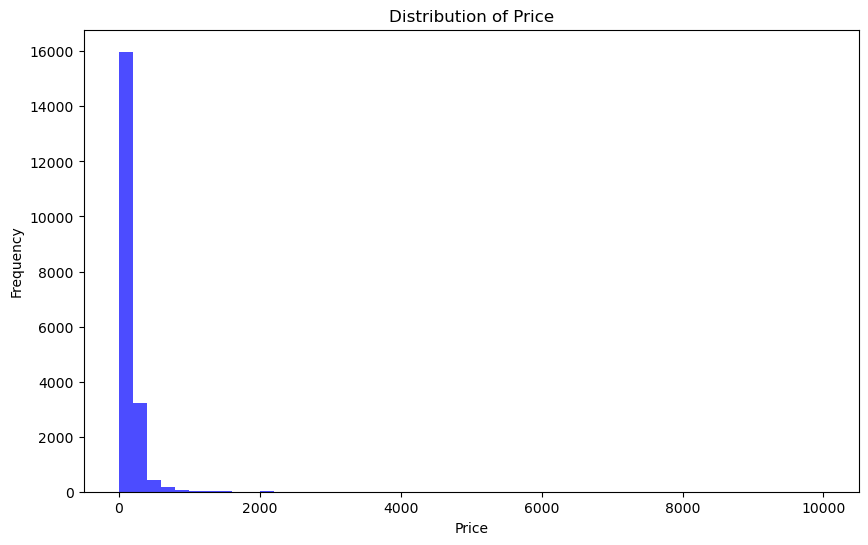

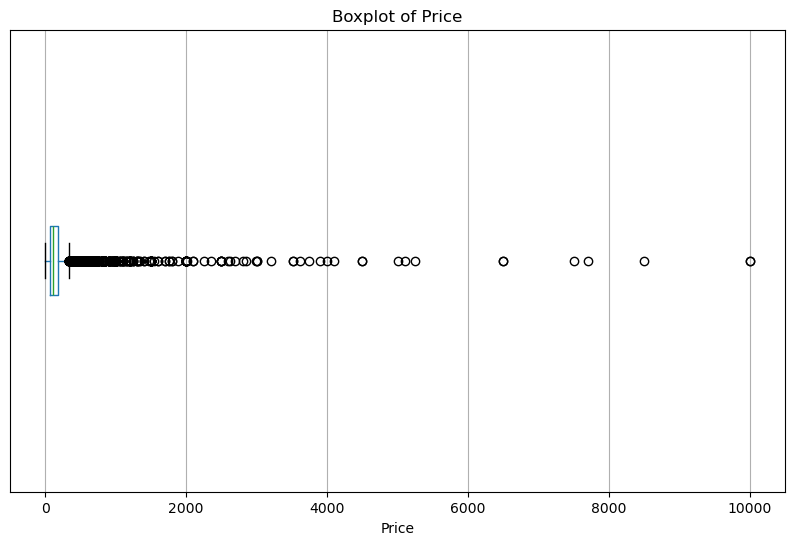

In [ ]:
import matplotlib.pyplot as plt
"""Use matplotlib to visualize the distribution of variables 
 with potentially extreme values, such as price and minimum_nights. 
 This will help us identify outliers and understand the data better."""

# Examine the distribution of price
# Histogram of price
plt.figure(figsize=(10, 6))
plt.hist(
    df['price'],
    bins=50,
    color='blue',
    alpha=0.7
)
plt.title('Distribution of Price')
plt.xlabel('Price')
plt.ylabel('Frequency')

# Boxplot of price
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='price',
    ax=ax,
    vert=False
)
ax.set_title('Boxplot of Price')
ax.set_xlabel('Price')
ax.set_yticks([])


plt.show();


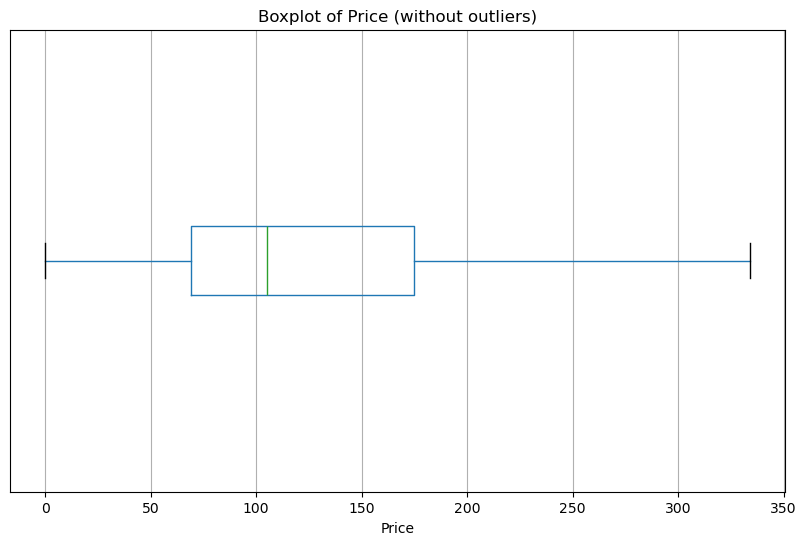

In [56]:
# Hide outlier markers so the boxes and whiskers are more visible
# Outliers remain in the data and are used to calculate the box plot.

fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='price',
    ax=ax,
    vert=False,
    showfliers=False
)
ax.set_title('Boxplot of Price (without outliers)')
ax.set_xlabel('Price')
ax.set_yticks([])

plt.show();


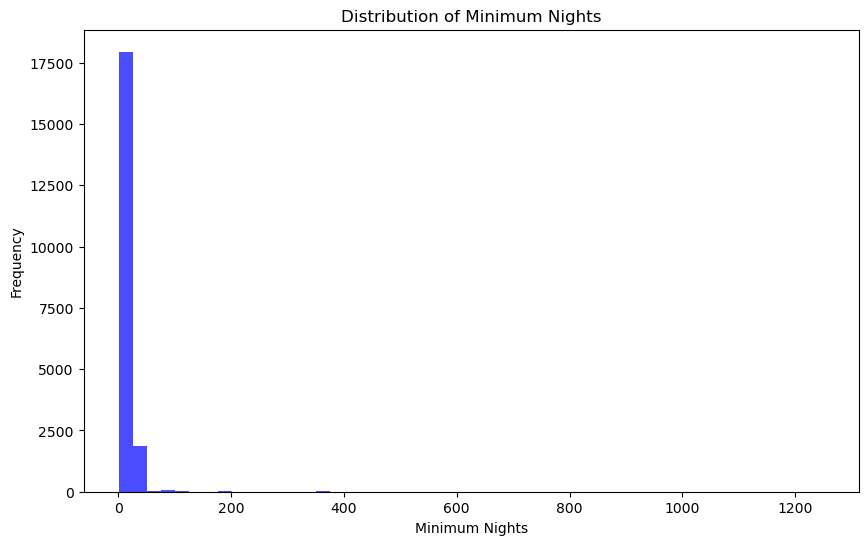

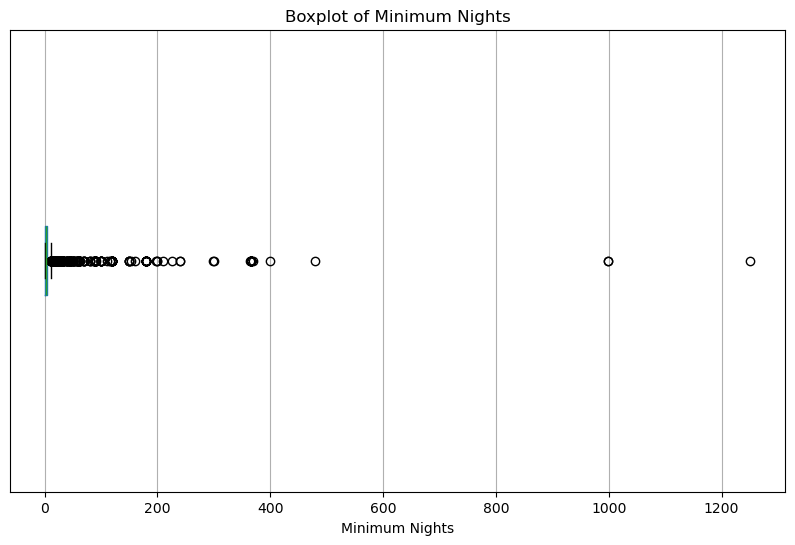

In [ ]:
# Examine the distribution of minimum_nights
# Histogram of minimum_nights
plt.figure(figsize=(10, 6))
plt.hist(
    df['minimum_nights'],
    bins=50,
    color='blue',
    alpha=0.7
)
plt.title('Distribution of Minimum Nights')
plt.xlabel('Minimum Nights')
plt.ylabel('Frequency')

# Boxplot of minimum_nights
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='minimum_nights',
    ax=ax,
    vert=False
)
ax.set_title('Boxplot of Minimum Nights')
ax.set_xlabel('Minimum Nights')
ax.set_yticks([])


plt.show();

[]

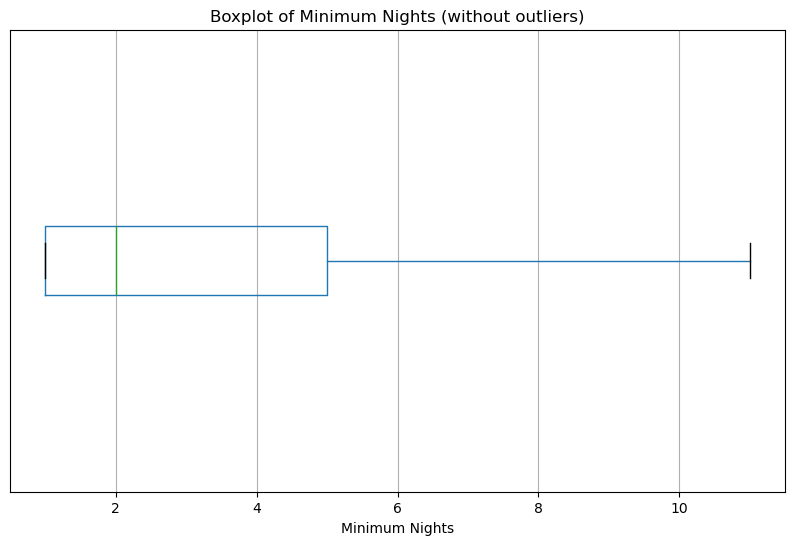

In [58]:
# Hide outlier markers so the boxes and whiskers are more visible
# Outliers remain in the data and are used to calculate the box plot.
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='minimum_nights',
    ax=ax,
    vert=False,
    showfliers = False
)
ax.set_title('Boxplot of Minimum Nights (without outliers)')
ax.set_xlabel('Minimum Nights')
ax.set_yticks([])


In [26]:
# How many records have a minimum_nights value of 0?
print(f'{df[df['minimum_nights'] > 90].shape[0]} properties have a minimum stay of approximately 3 months or longer.')
print(f'{df[df['minimum_nights'] > 180].shape[0]} properties have a minimum stay of approximately 6 months or longer.')
print(f'{df[df['minimum_nights'] >= 365].shape[0]} properties have a minimum stay of a year or longer.')

83 properties have a minimum stay of approximately 3 months or longer.
30 properties have a minimum stay of approximately 6 months or longer.
20 properties have a minimum stay of a year or longer.


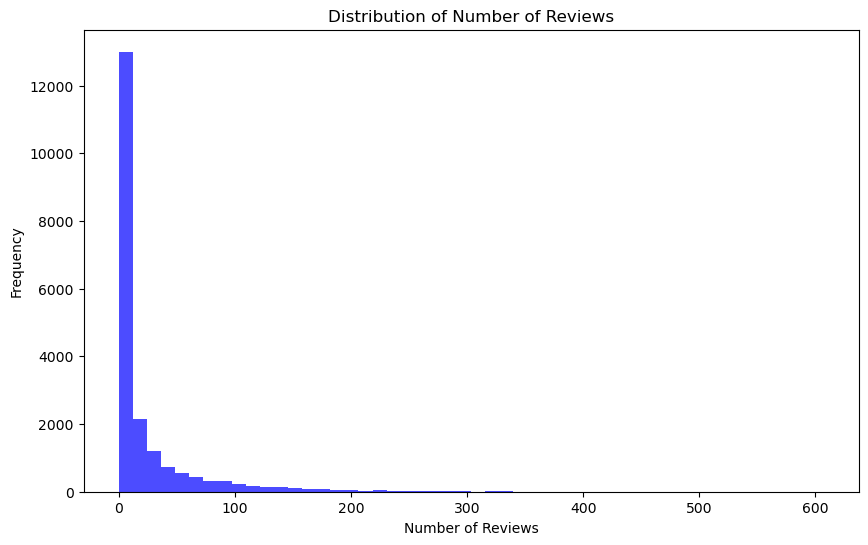

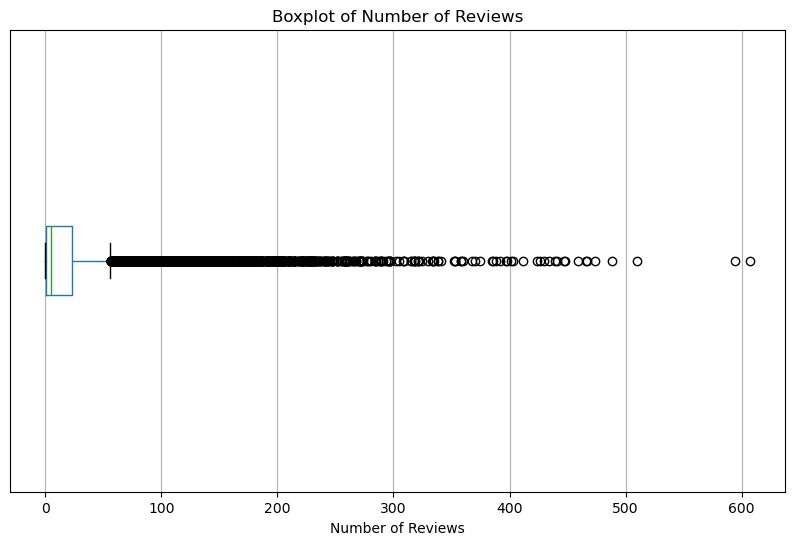

In [ ]:
# Examine the distribution of number_of_reviews
# Histogram of number_of_reviews
plt.figure(figsize=(10, 6))
plt.hist(
    df['number_of_reviews'],
    bins=50,
    color='blue',
    alpha=0.7
)
plt.title('Distribution of Number of Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Frequency')

# Boxplot of number_of_reviews
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='number_of_reviews',
    ax=ax,
    vert=False
)
ax.set_title('Boxplot of Number of Reviews')
ax.set_xlabel('Number of Reviews')
ax.set_yticks([])


plt.show();

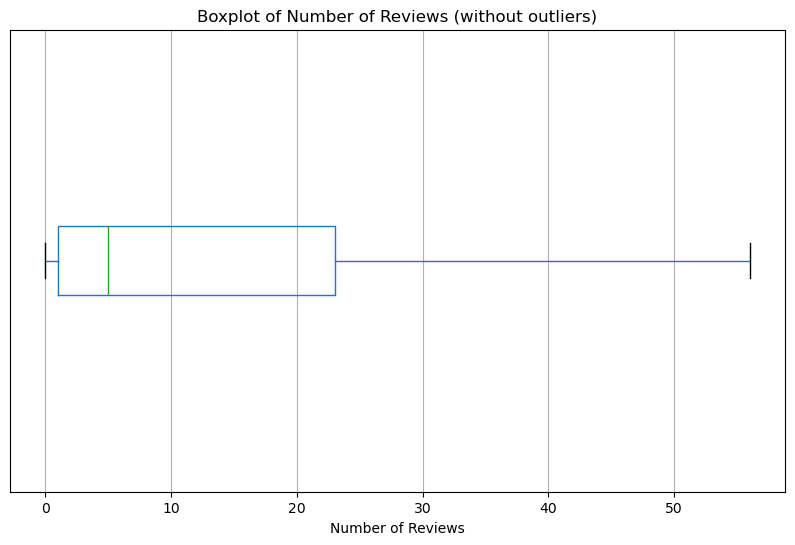

In [60]:
# Hide outlier markers so the boxes and whiskers are more visible
# Outliers remain in the data and are used to calculate the box plot.
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='number_of_reviews',
    ax=ax,
    vert=False,
    showfliers=False
)
ax.set_title('Boxplot of Number of Reviews (without outliers)')
ax.set_xlabel('Number of Reviews')
ax.set_yticks([])
plt.show()


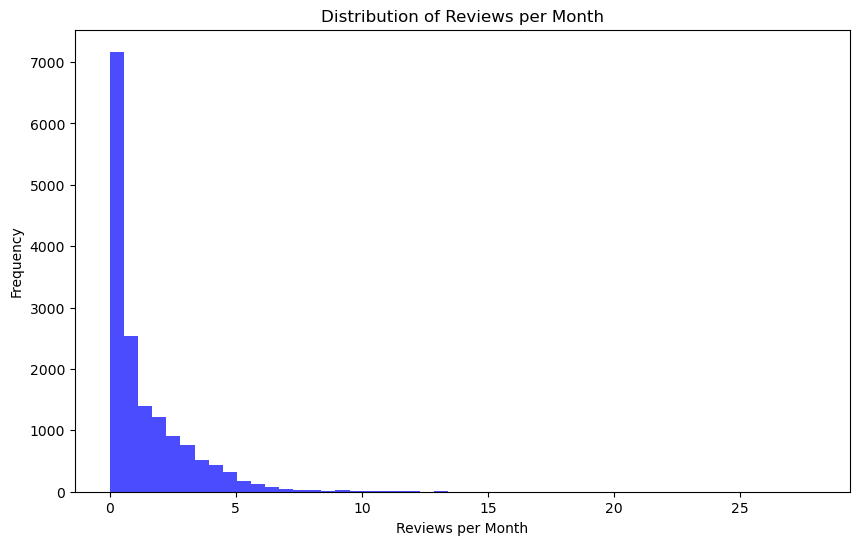

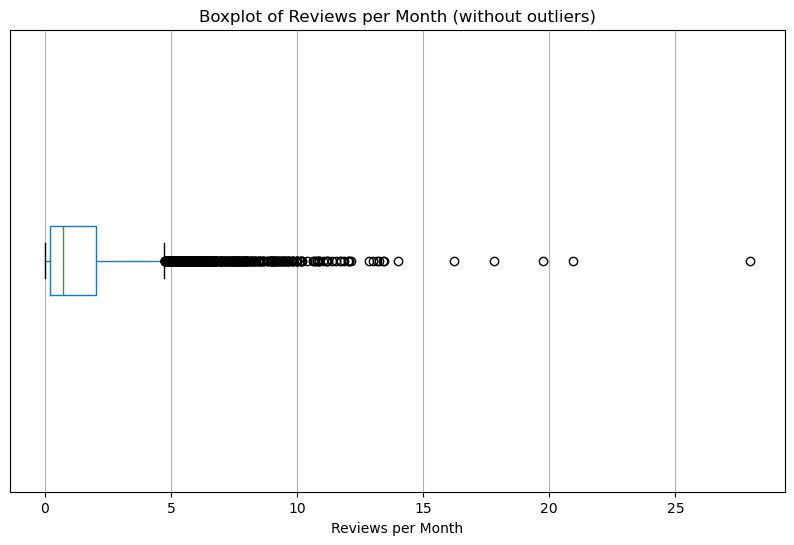

In [ ]:
# Examine the distribution of reviews_per_month
# Histogram of reviews_per_month
plt.figure(figsize=(10, 6))
plt.hist(
    df['reviews_per_month'].dropna(),
    bins=50,
    color='blue',
    alpha=0.7
)
plt.title('Distribution of Reviews per Month')
plt.xlabel('Reviews per Month')
plt.ylabel('Frequency') 

# Boxplot of reviews_per_month
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='reviews_per_month',
    ax=ax,
    vert=False
)
ax.set_title('Boxplot of Reviews per Month (without outliers)')
ax.set_xlabel('Reviews per Month')
ax.set_yticks([])

plt.show();

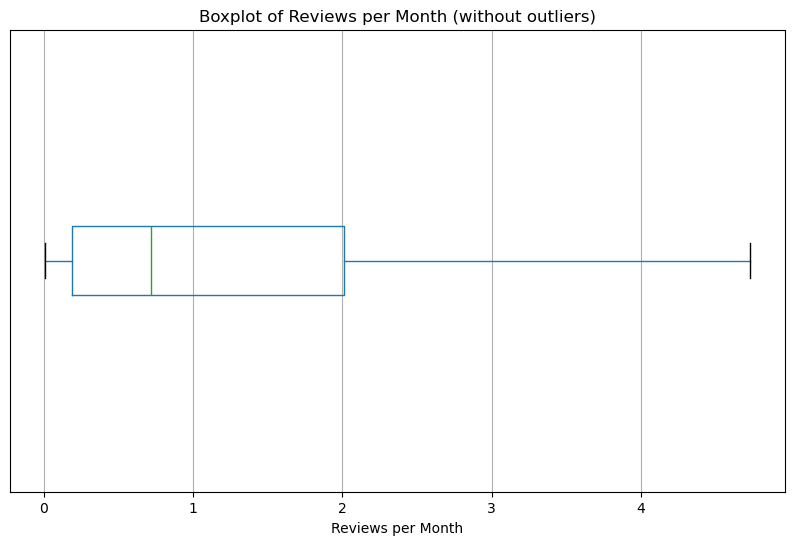

In [62]:
# Hide outlier markers so the boxes and whiskers are more visible
# Outliers remain in the data and are used to calculate the box plot.
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='reviews_per_month',
    ax=ax,
    vert=False,
    showfliers=False
)
ax.set_title('Boxplot of Reviews per Month (without outliers)')
ax.set_xlabel('Reviews per Month')
ax.set_yticks([])
plt.show()


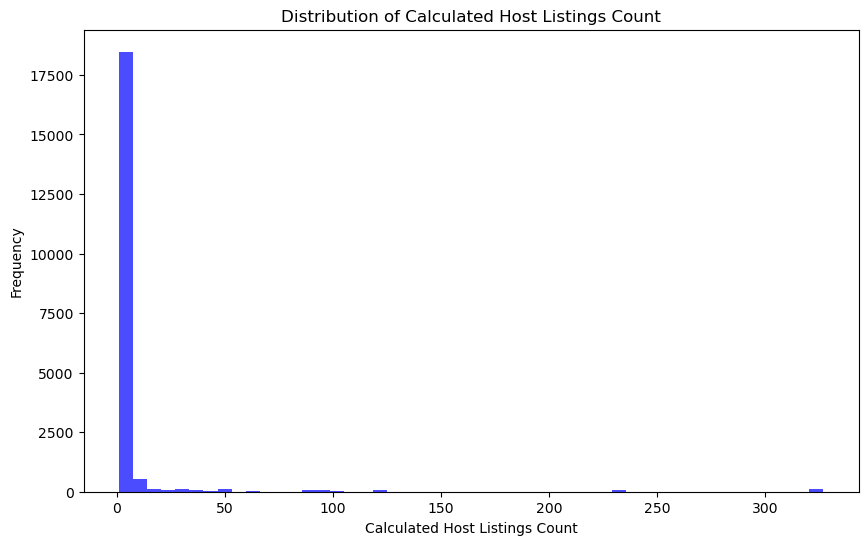

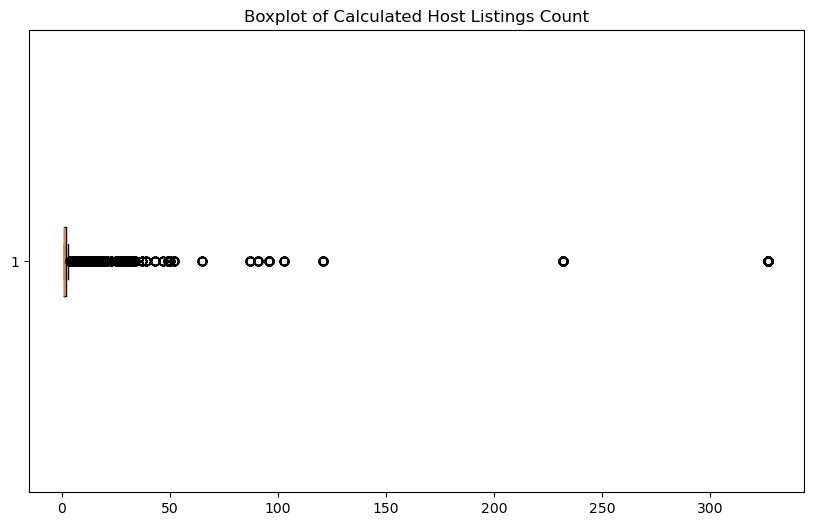

In [ ]:
# Examine the distribution of calculated_host_listings_count
# Histogram of calculated_host_listings_count
plt.figure(figsize=(10, 6))
plt.hist(
    df['calculated_host_listings_count'],
    bins=50,
    color='blue',
    alpha=0.7
)
plt.title('Distribution of Calculated Host Listings Count')
plt.xlabel('Calculated Host Listings Count')   
plt.ylabel('Frequency')

# Boxplot of calculated_host_listings_count
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='calculated_host_listings_count',
    ax=ax,
    vert=False
)
ax.set_title('Boxplot of Calculated Host Listings Count (without outliers)')
ax.set_xlabel('Calculated Host Listings Count')
ax.set_yticks([])
plt.show();


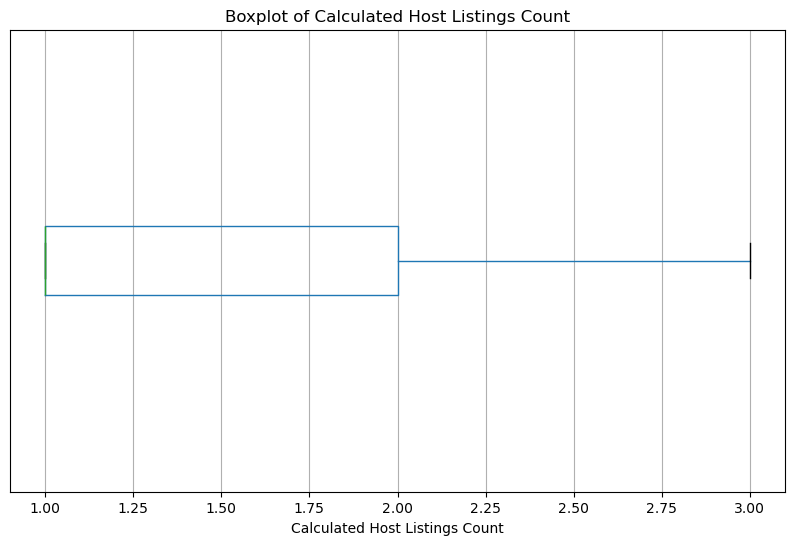

In [64]:
# Hide outlier markers so the boxes and whiskers are more visible
# Outliers remain in the data and are used to calculate the box plot.
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='calculated_host_listings_count',
    ax=ax,
    vert=False,
    showfliers=False
)
ax.set_title('Boxplot of Calculated Host Listings Count')
ax.set_xlabel('Calculated Host Listings Count')
ax.set_yticks([])
plt.show()


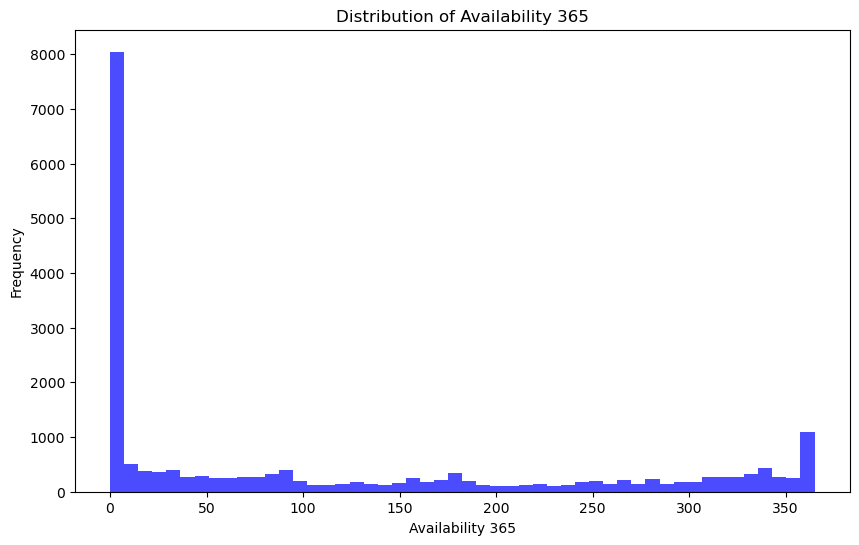

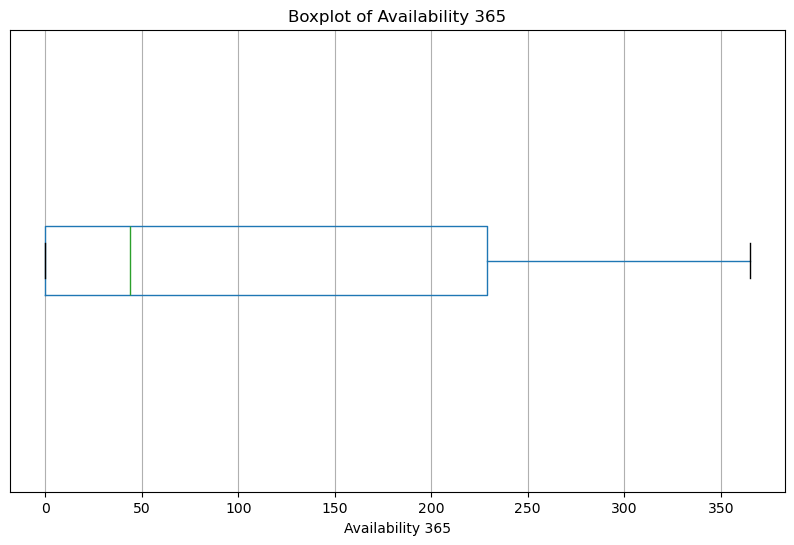

In [ ]:
# Examine the distribution of availability_365
# Histogram of availability_365
plt.figure(figsize=(10, 6))
plt.hist(
    df['availability_365'],
    bins=50,
    color='blue',
    alpha=0.7
)
plt.title('Distribution of Availability 365')
plt.xlabel('Availability 365')
plt.ylabel('Frequency')


# Boxplot of availability_365
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(
    column='availability_365',
    ax=ax,
    vert=False
)
ax.set_title('Boxplot of Availability 365')
ax.set_xlabel('Availability 365')
ax.set_yticks([])


plt.show();

3. What do you notice in the data? Look around and see what you can find.



>The 'name' column contains listing descriptions rather than owner or property names. There are 7 missing listing names and 8 missing host names. All records missing a listing name still have a host name.  

>Both 'last_review' and 'reviews_per_month' have 4,123 missing values. All of these records also have 0 reviews, suggesting the missing values reflect listings that have not received reviews.  The 'last_review' column is stored as an object (text) and should be converted to a datetime datatype.

>Several numeric columns have unusually high values worth investigating. For example, the values in the 'price' column range from $0 to $10,000, and the values in 'minimum_nights' range from 1 to 1,250 nights. 'number_of_reviews', 'reviews_per_month', and 'calculated_host_list_count' also have large maximum values. These values may be legitimate, so they should not automatically be removed.

>Availability ranges from 0 to 365 days ('availability_365'). Zero availability does not necessarily indicate an error because dates may be booked or blocked off by the owner. 

>For this project, the planned basic cleaning will retain records with prices between $10 and $350 and convert 'last_review' to datetime. Missing values will be handled later in the pipeline.

4. Fix some of the little problems we have found in the data with the following code:

In [68]:
# Drop outliers
min_price = 10
max_price = 350
idx = df['price'].between(min_price, max_price)
df = df[idx].copy()

# Convert last_review to datetime
df['last_review'] = pd.to_datetime(df['last_review'])

Note how we did not impute missing values. We will do that in the inference pipeline, so we will be able to handle missing values also in production.

5. Check with df.info() that all obvious problems have been solved

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19001 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              19001 non-null  int64         
 1   name                            18994 non-null  object        
 2   host_id                         19001 non-null  int64         
 3   host_name                       18993 non-null  object        
 4   neighbourhood_group             19001 non-null  object        
 5   neighbourhood                   19001 non-null  object        
 6   latitude                        19001 non-null  float64       
 7   longitude                       19001 non-null  float64       
 8   room_type                       19001 non-null  object        
 9   price                           19001 non-null  int64         
 10  minimum_nights                  19001 non-null  int64         
 11  number_

In [70]:
df['price'].describe()

count    19001.000000
mean       122.340456
std         71.530346
min         10.000000
25%         66.000000
50%        100.000000
75%        160.000000
max        350.000000
Name: price, dtype: float64

6. Terminate the run by running `run.finish()`

In [71]:
run.finish()

wandb: ERROR Unable to save notebook session history.


7. Save the notebook.

In [ ]:
# Upload the latest saved EDA notebook to W&B without rerunning the analysis.
with wandb.init(
    entity="smcwate-western-governors-university",
    project="nyc_airbnb",
    group="eda",
    job_type="notebook_upload"
) as upload_run:
    upload_run.log_code(
        root=".",
        include_fn=lambda path: path.endswith("eda.ipynb")
    ) 
